# Staying at a good solution once the network is fully connected

A block-sparse network first learns the problem. Halfway through training it becomes fully connected, so every added
connection is a distractor. Does our method from `01_distractors.ipynb` stay at the good solution?

**Problem.** As in `02_nonstationary.ipynb`: 2-task simple multi-GEOFF where each task has 21 inputs, 10
zero-threshold teacher LTUs, and 10 outputs plus $N(0, 1)$ noise. The inputs and every teacher weight are random
$\pm 1$ signs. Every 1000 steps, one task (chosen at random) has the columns of its output weights permuted.

**Network.** 42 inputs → 20 LTU hidden units (10 per task) → 20 linear outputs, each layer with a bias. For the first
500k steps it is block-sparse: every hidden unit reads only its own task's inputs and feeds only its own task's
outputs. From step 500k it is fully connected, adding every cross-task connection (420 input, 200 output). The added
connections start at weight 0 with untouched Autostep traces, and at step-size $\alpha_0$ unless Autostep's per-row
normalization has already lowered it (it scales every step-size in a row whose total is over 1).

**Learners.** As in `02_nonstationary.ipynb`, with $\alpha_0 = 10^{-8}$, meta step-size 0.01 and $\tau = 10^4$:
- *ours*: centered hidden units with a matching centered backward pass, and input weights starting at
  $U(-\alpha_0, \alpha_0)$;
- *standard Autostep*: raw hidden units, and input weights starting LeCun uniform.

Each learner runs twice: fully connected from 500k, and kept block-sparse throughout as its reference. 1M steps and 30
seeds; seed $s$ gives every run the same teacher and the same perturbations. Everything is recorded at step 1, then
averaged over each window of 4000 steps. The learning curve shows the RMSE over outputs (its minimum, the noise, is 1),
mean $\pm 2$ SE over seeds.

**Hypotheses**, on the excess MSE (above the noise floor) pooled over seeds, in two windows: the 100k steps right after
the switch, and the last 10% of training:
- **H1**, ours stays at the good solution: in both windows, ours is at most 1% above ours kept sparse.
- **H2**, the switch is a real test: in at least one window, standard Autostep is more than 1% above standard Autostep
  kept sparse.

**Diagnostic**, fixed in advance: for ours, the added connections' $\beta = \ln(\alpha)$, the log step-size, and $|w|$
against the useful weights' after the switch.

In [1]:
from typing import NamedTuple

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import IDBDState, optax_idbd
from phd.jax_core.tasks.simple_multi_geoff import SimpleMultiGEOFFTask
from phd.jax_core.utils import stack_pytrees

sns.set_theme('notebook', 'whitegrid')
%matplotlib inline

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# --- Problem ---
N_TASKS = 2
N_INPUTS_PER_TASK = 21
N_TEACHER_LTUS_PER_TASK = 10
N_OUTPUTS_PER_TASK = 10
NOISE_STD = 1.0
PERTURB_PERIOD = 1000                # steps between perturbations, each of one task chosen at random

# --- Network ---
N_HIDDEN_PER_TASK = 10
SWITCH_STEP = 500_000                # block-sparse before this step, fully connected after it

# --- Autostep ---
INIT_STEP_SIZE = 1e-8
META_STEP_SIZE = 0.01
TAU = 1e4
EMA_RATE = 1e-3                      # rate of the hidden units' running means (used by ours)

# --- Training ---
NUM_STEPS = 1_000_000
N_SEEDS = 30
N_WINDOWS = 250                      # each window records the mean of the loss and of every recorded beta and |w|

# --- Hypotheses ---
AFTER_SWITCH = 100_000               # the loss is compared over the steps right after the switch ...
FINAL_FRACTION = 0.1                 # ... and over the last 10% of training ...
LOSS_TOLERANCE = 0.01                # ... with this relative tolerance

In [3]:
LAYERS = ('w1', 'w2')
N_HIDDEN = N_TASKS * N_HIDDEN_PER_TASK
N_OUTPUTS = N_TASKS * N_OUTPUTS_PER_TASK

input_task = np.repeat(np.arange(N_TASKS), N_INPUTS_PER_TASK)
hidden_task = np.repeat(np.arange(N_TASKS), N_HIDDEN_PER_TASK)
output_task = np.repeat(np.arange(N_TASKS), N_OUTPUTS_PER_TASK)


def with_bias_column(mask, bias):
    # The last column of each weight matrix reads the constant-1 input.
    return np.concatenate([mask, np.full((mask.shape[0], 1), bias)], axis=1)


# Masks are shaped like the weight matrices: w1 is (hidden, inputs + 1), w2 is (outputs, hidden + 1).
same_task = {'w1': hidden_task[:, None] == input_task[None, :],
             'w2': output_task[:, None] == hidden_task[None, :]}
USEFUL = {k: with_bias_column(m, False) for k, m in same_task.items()}
DISTRACTORS = {k: with_bias_column(~m, False) for k, m in same_task.items()}     # every cross-task connection
SPARSE = {k: with_bias_column(m, True) for k, m in same_task.items()}            # the useful weights and the biases
FULL = {k: np.ones_like(m) for k, m in SPARSE.items()}

for k in LAYERS:
    print(f'{k}: {USEFUL[k].sum()} useful, {DISTRACTORS[k].sum()} distractors once fully connected, '
          f'{SPARSE[k].shape[0]} biases')

w1: 420 useful, 420 distractors once fully connected, 20 biases
w2: 200 useful, 200 distractors once fully connected, 20 biases


## Learner

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_STEP_SIZE, init_lr=INIT_STEP_SIZE, autostep=True, tau=TAU,
                       version='squared_inputs')


class Learner(NamedTuple):
    w: dict                   # {'w1': ..., 'w2': ...}; masked-out weights stay at exactly 0 (their gradient is 0)
    opt: IDBDState
    hidden_mean: jax.Array    # each hidden unit's running mean firing rate
    hidden_slope: jax.Array   # running mean of sigma'(z) x, each hidden unit's derivative w.r.t. each input weight


def init_learner(key, masks, ours):
    # Input weights: U(-INIT_STEP_SIZE, INIT_STEP_SIZE) for ours, LeCun uniform over each unit's inputs otherwise. Both
    # scale the same draw.
    fan_in = masks['w1'][:, :-1].sum(1, keepdims=True)
    bound = INIT_STEP_SIZE if ours else np.sqrt(3.0 / fan_in)
    w1 = jax.random.uniform(key, masks['w1'].shape, minval=-1.0, maxval=1.0) * bound * masks['w1']
    w = {'w1': w1.at[:, -1].set(0.0), 'w2': jnp.zeros(masks['w2'].shape)}
    # A zero-threshold LTU with symmetric inputs fires with probability 1/2, so the means start out exact. The slope
    # starts at sigma'(0) E[x]: 0 for the zero-mean inputs, 1/4 for the bias.
    return Learner(w, OPTIMIZER.init(w), jnp.full(N_HIDDEN, 0.5), jnp.zeros(masks['w1'].shape).at[:, -1].set(0.25))


def forward(w, x, learner, masks, ours):
    # Returns the prediction, each weight's source values (what Autostep normalizes by), and the new running means.
    x = jnp.append(x, 1.0)
    w1 = w['w1'] * masks['w1']
    z = w1 @ x
    h = ltu(z)

    # Running means, updated with this sample before they are used. No gradient flows through them.
    mean = learner.hidden_mean + EMA_RATE * (jax.lax.stop_gradient(h) - learner.hidden_mean)
    sigma_prime = jax.lax.stop_gradient(jax.nn.sigmoid(z) * (1.0 - jax.nn.sigmoid(z)))     # the LTU's surrogate slope
    slope = learner.hidden_slope + EMA_RATE * (sigma_prime[:, None] * x[None, :] - learner.hidden_slope)
    if ours:
        # Send h - m, with the gradient of h - E[h]: each input weight's derivative becomes sigma'(z) x - slope. The
        # correction leaves the value unchanged.
        correction = jnp.sum(slope * w1, axis=1)
        h = h - mean - correction + jax.lax.stop_gradient(correction)

    h = jnp.append(h, 1.0)
    y_hat = (w['w2'] * masks['w2']) @ h
    return y_hat, ({'w1': x[None], 'w2': h[None]}, mean, slope)


def learner_step(learner, x, y, masks, ours):
    # One online Autostep update. Returns the new learner and the squared error summed over outputs.
    def loss_fn(w):
        y_hat, aux = forward(w, x, learner, masks, ours)
        return 0.5 * jnp.sum((y_hat - y) ** 2), aux

    (loss, (source_values, mean, slope)), grads = jax.value_and_grad(loss_fn, has_aux=True)(learner.w)
    updates, opt = OPTIMIZER.update((grads, None, source_values), learner.opt, learner.w)
    w = {k: learner.w[k] + updates[k] for k in LAYERS}
    return Learner(w, opt, mean, slope), 2.0 * loss

## Training

In [5]:
RECORDED = {'useful': USEFUL, 'distractors': DISTRACTORS}
STEPS_PER_WINDOW = NUM_STEPS // N_WINDOWS


def recorded_values(learner):
    # beta (log step-size) and |w| of the useful weights and of the distractors, flattened per layer.
    return {group: {k: {'beta': learner.opt.beta[k][mask[k]], 'w': jnp.abs(learner.w[k])[mask[k]]} for k in LAYERS}
            for group, mask in RECORDED.items()}


def masks_at(dense):
    # The block-sparse masks, or the fully connected ones once `dense` is true. A masked-out weight's Autostep state
    # never moves (its gradient is 0), so a connection added at the switch starts at weight 0 and step-size
    # INIT_STEP_SIZE, with zero traces.
    return {k: jnp.where(dense, FULL[k], SPARSE[k]) for k in LAYERS}


def train(key, task, ours, switch):
    # Step 1 on its own, then NUM_STEPS online steps in windows: block-sparse throughout, or (with `switch`) fully
    # connected from SWITCH_STEP. Returns the per-output MSE, and the recorded weights' beta and |w|: at step 1, then
    # averaged over every window.
    def window(carry, index):
        learner, task = carry
        masks = masks_at(jnp.logical_and(switch, index >= SWITCH_STEP // STEPS_PER_WINDOW))

        def one_step(carry, _):
            learner, task, total = carry
            task, (x, y) = task.generate_batch(1)
            learner, sq_err = learner_step(learner, x[0], y[0], masks, ours)
            total = jax.tree.map(jnp.add, total, recorded_values(learner))
            return (learner, task, total), sq_err

        zeros = jax.tree.map(jnp.zeros_like, recorded_values(learner))
        (learner, task, total), sq_err = jax.lax.scan(one_step, (learner, task, zeros), length=STEPS_PER_WINDOW)
        return (learner, task), (sq_err.mean() / N_OUTPUTS, jax.tree.map(lambda t: t / STEPS_PER_WINDOW, total))

    task, (x, y) = task.generate_batch(1)
    learner, sq_err = learner_step(init_learner(key, SPARSE, ours), x[0], y[0], SPARSE, ours)
    _, (mse, values) = jax.lax.scan(window, (learner, task), jnp.arange(N_WINDOWS))
    first = (sq_err / N_OUTPUTS, recorded_values(learner))
    return jax.tree.map(lambda f, v: jnp.concatenate([f[None], v]), first, (mse, values))


def seeds():
    # Init keys and teachers. Seed s uses teacher s (and its perturbations) and init key s for every run, so runs are
    # paired.
    tasks = stack_pytrees([
        SimpleMultiGEOFFTask(N_TASKS, perturb_period=PERTURB_PERIOD, n_features_per_task=N_INPUTS_PER_TASK,
                             n_hidden_per_task=N_TEACHER_LTUS_PER_TASK, n_outputs_per_task=N_OUTPUTS_PER_TASK,
                             noise_std=NOISE_STD, seed=s)
        for s in range(N_SEEDS)])
    return jax.random.split(jax.random.PRNGKey(0), N_SEEDS), tasks


def run(ours, switch):
    # Trains one learner (ours, or standard Autostep) on every seed, vmapped into one scan: block-sparse throughout, or
    # fully connected from SWITCH_STEP. Returns the excess MSE and the RMSE (seed, step 1 + window), and
    # values[group][layer][quantity] (seed, step 1 + window, weight).
    keys, tasks = seeds()
    mse, values = jax.jit(jax.vmap(lambda key, task: train(key, task, ours, switch)))(keys, tasks)
    mse = np.asarray(mse)
    return {'excess_mse': mse - NOISE_STD ** 2, 'rmse': np.sqrt(mse), **jax.tree.map(np.asarray, values)}

## Results

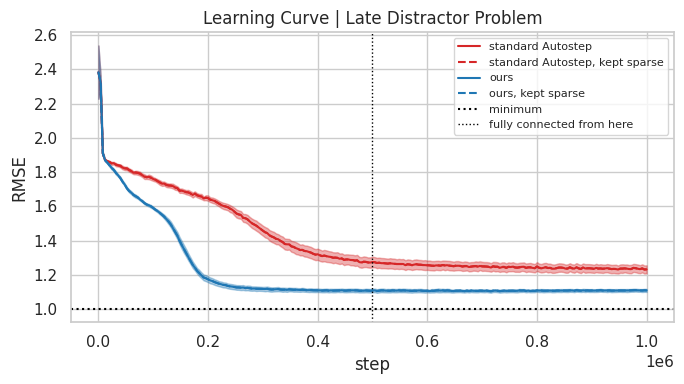

right after the switch:
  standard Autostep                excess MSE 0.6010
  standard Autostep, kept sparse   excess MSE 0.6018
  ours                             excess MSE 0.2274
  ours, kept sparse                excess MSE 0.2274
  ours vs kept sparse: -0.0% (± 0.0%, 2 SE over paired seeds)
  standard Autostep vs kept sparse: -0.1% (± 0.2%, 2 SE over paired seeds)
last 10%:
  standard Autostep                excess MSE 0.5306
  standard Autostep, kept sparse   excess MSE 0.5313
  ours                             excess MSE 0.2295
  ours, kept sparse                excess MSE 0.2295
  ours vs kept sparse: +0.0% (± 0.1%, 2 SE over paired seeds)
  standard Autostep vs kept sparse: -0.1% (± 1.3%, 2 SE over paired seeds)
H1, ours at most 1% above ours kept sparse in both windows: held
H2, standard Autostep more than 1% above it kept sparse in a window: failed


In [6]:
runs = {'standard Autostep': run(ours=False, switch=True),
        'standard Autostep, kept sparse': run(ours=False, switch=False),
        'ours': run(ours=True, switch=True),
        'ours, kept sparse': run(ours=True, switch=False)}
# Color by learner; dashed for the runs kept block-sparse.
STYLES = {'standard Autostep': ('tab:red', '-'), 'standard Autostep, kept sparse': ('tab:red', '--'),
          'ours': ('tab:blue', '-'), 'ours, kept sparse': ('tab:blue', '--')}

steps = 1 + np.arange(N_WINDOWS + 1) * STEPS_PER_WINDOW     # step 1, then the end of every window
plt.figure(figsize=(7, 4))
for label, res in runs.items():
    mean = res['rmse'].mean(0)
    sem = res['rmse'].std(0) / np.sqrt(N_SEEDS)
    color, linestyle = STYLES[label]
    plt.plot(steps, mean, color=color, ls=linestyle, lw=1.5, label=label)
    plt.fill_between(steps, mean - 2 * sem, mean + 2 * sem, color=color, alpha=0.2)
plt.axhline(NOISE_STD, color='black', lw=1.5, ls=':', label='minimum')
plt.axvline(SWITCH_STEP, color='black', lw=1, ls=':', label='fully connected from here')
plt.xlabel('step')
plt.ylabel('RMSE')
plt.title('Learning Curve | Late Distractor Problem')
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Each seed's excess MSE in each window: the AFTER_SWITCH steps right after the switch, and the last FINAL_FRACTION of
# training.
first = 1 + SWITCH_STEP // STEPS_PER_WINDOW     # the first window after the switch (record 0 is step 1)
windows = {'right after the switch': slice(first, first + AFTER_SWITCH // STEPS_PER_WINDOW),
           'last 10%': slice(-round(N_WINDOWS * FINAL_FRACTION), None)}
loss = {w: {label: res['excess_mse'][:, s].mean(1) for label, res in runs.items()} for w, s in windows.items()}


def gap(window, label):
    # The per-seed gap of `label` to the same learner kept sparse, on the same seed, relative to the kept-sparse run's
    # mean: its mean and 2 SE.
    reference = loss[window][f'{label}, kept sparse']
    g = (loss[window][label] - reference) / reference.mean()
    return g.mean(), 2 * g.std() / np.sqrt(N_SEEDS)


gaps = {w: {label: gap(w, label) for label in ('ours', 'standard Autostep')} for w in windows}
for w in windows:
    print(f'{w}:')
    for label, l in loss[w].items():
        print(f'  {label:<32} excess MSE {l.mean():.4f}')
    for label, (g, se) in gaps[w].items():
        print(f'  {label} vs kept sparse: {g:+.1%} (± {se:.1%}, 2 SE over paired seeds)')
held = lambda ok: 'held' if ok else 'failed'
print(f'H1, ours at most {LOSS_TOLERANCE:.0%} above ours kept sparse in both windows: '
      f'{held(all(gaps[w]["ours"][0] <= LOSS_TOLERANCE for w in windows))}')
print(f'H2, standard Autostep more than {LOSS_TOLERANCE:.0%} above it kept sparse in a window: '
      f'{held(any(gaps[w]["standard Autostep"][0] > LOSS_TOLERANCE for w in windows))}')

### Diagnostic: added connections against useful weights

Ours, in each layer: the mean of $\beta$ and the median of $|w|$, with the 5th to 95th percentile shaded, pooled over
seeds. The added connections are shown from the switch on.

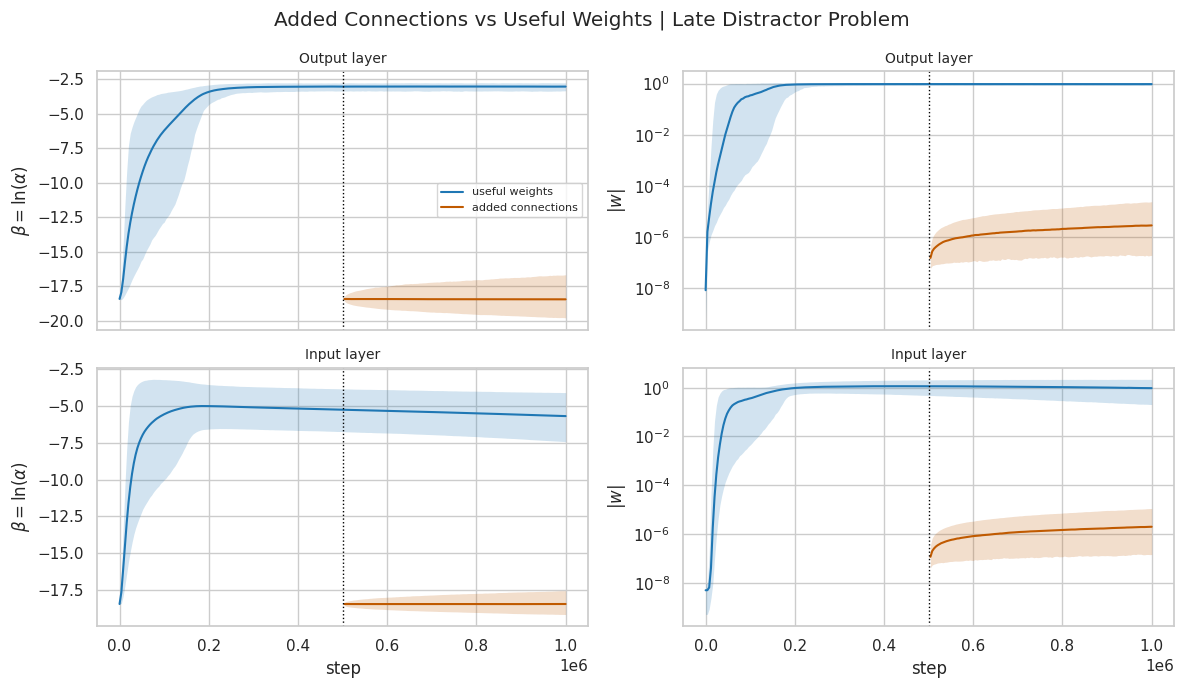

In [7]:
connected = np.arange(N_WINDOWS + 1) > SWITCH_STEP // STEPS_PER_WINDOW    # windows after the switch (0 is step 1)
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
columns = [('beta', '$\\beta = \\ln(\\alpha)$', np.mean, 'linear'), ('w', '$|w|$', np.median, 'log')]
for row, (name, layer) in zip(axes, [('Output', 'w2'), ('Input', 'w1')]):
    for ax, (quantity, ylabel, center, yscale) in zip(row, columns):
        for (group, label), color in zip([('useful', 'useful weights'), ('distractors', 'added connections')],
                                         ('#1f77b4', '#c05a00')):
            v = runs['ours'][group][layer][quantity].transpose(1, 0, 2).reshape(len(steps), -1)
            if group == 'distractors':
                v = np.where(connected[:, None], v, np.nan)
            ax.plot(steps, center(v, axis=1), color=color, lw=1.5, label=label)
            ax.fill_between(steps, *np.percentile(v, [5, 95], axis=1), color=color, alpha=0.2, lw=0)
        ax.axvline(SWITCH_STEP, color='black', lw=1, ls=':')
        ax.set_yscale(yscale)
        ax.set_title(f'{name} layer', fontsize=10)
        ax.set_ylabel(ylabel)
for ax in axes[1]:
    ax.set_xlabel('step')
axes[0, 0].legend(fontsize=8)
fig.suptitle('Added Connections vs Useful Weights | Late Distractor Problem')
fig.tight_layout()
plt.show()

## Results

- **H1 held.** Ours is −0.0% (± 0.0%, 2 SE over paired seeds) above ours kept sparse in the 100k steps right after the
  switch, and +0.0% (± 0.1%) over the last 10%.
- **H2 failed.** Standard Autostep is unaffected too: −0.1% (± 0.2%) right after the switch, and −0.1% (± 1.3%) over
  the last 10%. So this switch does not tell the learners apart: neither is hurt by connections added to a trained
  network.
- **Why it is easy for both** (checked afterwards, not a pre-set diagnostic): by the end, the added connections' $|w|$
  is below $5 \cdot 10^{-5}$ at the 95th percentile for both learners. They start at 0 with a tiny step-size, and the
  two harms found in `01_distractors.ipynb` are likely absent: input distractors starting far from 0, and output
  distractors soaking up the outputs' mean error early in training (here the outputs' means are already learned, and
  the perturbations keep each output's mean). For standard Autostep, the per-row normalization had also
  lowered the step-sizes of 42% of the added input connections before the switch (median $\beta$ −18.9 among them,
  instead of −18.4). Its added output connections are not all quiet, though: in 12 of 30 seeds a few of them grow above
  $10^{-3}$, the largest to about 1 by the end.
- **Diagnostic.** In ours, the added connections' mean $\beta$ stays at −18.4 while their spread slowly widens (the
  output connections' 95th percentile reaches about −16.7 by 1M steps), and the useful weights do not react to the
  switch.